In [1]:
import urllib.request, json
import pandas as pd
from datetime import datetime, timezone
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

In [2]:
ticker = 'KO'
today = int(datetime.now().timestamp())

#query_url=f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?symbol={ticker}"
query_url1=f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?symbol={ticker}&period1=0&period2={today}&interval=1d&includePrePost=true&events=div%2Csplit"

def get_historic_price(query_url):
    # Fetch data from the URL
    try:
        with urllib.request.urlopen(query_url) as url:
            parsed = json.loads(url.read().decode())
    except Exception as e:
        print(f"Error fetching data: {e}")
        return

    # Check if 'chart' and 'result' keys exist
    if 'chart' not in parsed or 'result' not in parsed['chart'] or not parsed['chart']['result']:
        print(f"No data available for the ticker.")
        return
    
    # Extract data from the JSON response
    try:
        Date = []
        for i in parsed['chart']['result'][0]['timestamp']:
            Date.append(datetime.fromtimestamp(int(i), timezone.utc).strftime('%d-%m-%Y'))

        Low = parsed['chart']['result'][0]['indicators']['quote'][0]['low']
        Open = parsed['chart']['result'][0]['indicators']['quote'][0]['open']
        Volume = parsed['chart']['result'][0]['indicators']['quote'][0]['volume']
        High = parsed['chart']['result'][0]['indicators']['quote'][0]['high']
        Close = parsed['chart']['result'][0]['indicators']['quote'][0]['close']
        
        # Create a DataFrame
        df = pd.DataFrame(list(zip(Date, Open, High, Low, Close, Volume)), 
                        columns=['Date', 'Open', 'High', 'Low', 'Close', 'Volume'])
        
        print(f"Stock price for {ticker} is: ", parsed['chart']['result'][0]['meta']['regularMarketPrice'])
        return df
    
    except KeyError as e:
        print(f"Missing key in API response: {e}")
        return

KO = get_historic_price(query_url1)
print(KO)

Stock price for KO is:  64.05
             Date       Open       High        Low      Close    Volume
0      02-01-1970   0.856771   0.856771   0.850260   0.856771   1104000
1      05-01-1970   0.854167   0.854167   0.841146   0.843750    556800
2      06-01-1970   0.843750   0.854167   0.839844   0.851563    796800
3      07-01-1970   0.851563   0.859375   0.846354   0.856771    700800
4      08-01-1970   0.856771   0.864583   0.851563   0.858073   1065600
...           ...        ...        ...        ...        ...       ...
13885  24-01-2025  61.720001  62.009998  61.439999  61.919998  19244600
13886  27-01-2025  62.869999  64.180000  62.470001  63.869999  20742900
13887  28-01-2025  63.509998  64.040001  62.279999  62.360001  14956000
13888  29-01-2025  62.560001  63.360001  62.549999  62.830002  11321800
13889  30-01-2025  63.849998  64.285004  63.230000  64.050003  10176378

[13890 rows x 6 columns]


In [3]:
ticker = 'PEP'
today = int(datetime.now().timestamp())

#query_url=f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?symbol={ticker}"
query_url1=f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?symbol={ticker}&period1=0&period2={today}&interval=1d&includePrePost=true&events=div%2Csplit"

def get_historic_price(query_url):
    # Fetch data from the URL
    try:
        with urllib.request.urlopen(query_url) as url:
            parsed = json.loads(url.read().decode())
    except Exception as e:
        print(f"Error fetching data: {e}")
        return

    # Check if 'chart' and 'result' keys exist
    if 'chart' not in parsed or 'result' not in parsed['chart'] or not parsed['chart']['result']:
        print(f"No data available for the ticker.")
        return
    
    # Extract data from the JSON response
    try:
        Date = []
        for i in parsed['chart']['result'][0]['timestamp']:
            Date.append(datetime.fromtimestamp(int(i), timezone.utc).strftime('%d-%m-%Y'))

        Low = parsed['chart']['result'][0]['indicators']['quote'][0]['low']
        Open = parsed['chart']['result'][0]['indicators']['quote'][0]['open']
        Volume = parsed['chart']['result'][0]['indicators']['quote'][0]['volume']
        High = parsed['chart']['result'][0]['indicators']['quote'][0]['high']
        Close = parsed['chart']['result'][0]['indicators']['quote'][0]['close']
        
        # Create a DataFrame
        df = pd.DataFrame(list(zip(Date, Open, High, Low, Close, Volume)), 
                        columns=['Date', 'Open', 'High', 'Low', 'Close', 'Volume'])
        
        print(f"Stock price for {ticker} is: ", parsed['chart']['result'][0]['meta']['regularMarketPrice'])
        return df
    
    except KeyError as e:
        print(f"Missing key in API response: {e}")
        return

PEP = get_historic_price(query_url1)
print(PEP)

Stock price for PEP is:  151.9
             Date        Open        High         Low       Close   Volume
0      01-06-1972    0.000000    1.601852    1.583333    1.601852   318600
1      02-06-1972    1.601852    1.618056    1.597222    1.597222   140400
2      05-06-1972    1.597222    1.599537    1.543981    1.574074   469800
3      06-06-1972    1.560185    1.560185    1.555556    1.560185   140400
4      07-06-1972    1.560185    1.562500    1.546296    1.550926   178200
...           ...         ...         ...         ...         ...      ...
13273  24-01-2025  148.820007  149.309998  148.130005  149.119995  4509600
13274  27-01-2025  150.919998  155.470001  150.899994  154.610001  9820600
13275  28-01-2025  154.149994  154.610001  150.119995  150.250000  6349700
13276  29-01-2025  151.130005  152.000000  150.229996  150.369995  4862400
13277  30-01-2025  151.279999  153.080002  150.630005  151.899994  4641275

[13278 rows x 6 columns]


In [4]:
KO = KO[['Date', 'Close']]

PEP = PEP[['Date', 'Close']]

In [5]:
KO['Date'] = pd.to_datetime(KO['Date'], dayfirst=True)

PEP['Date'] = pd.to_datetime(PEP['Date'], dayfirst=True)

In [7]:
KO = KO[(KO['Date'] > '2015-01-01') & (KO['Date'] < '2016-01-01')].reset_index(drop=True)

PEP = PEP[(PEP['Date'] > '2015-01-01') & (PEP['Date'] < '2016-01-01')].reset_index(drop=True)


In [6]:
KO = KO[(KO['Date'] > '2023-01-01')].reset_index(drop=True)

PEP = PEP[(PEP['Date'] > '2023-01-01')].reset_index(drop=True)


In [7]:
KO.head()

,Date,Close
0,2023-01-03,62.950001
1,2023-01-04,62.919998
2,2023-01-05,62.200001
3,2023-01-06,63.400002
4,2023-01-09,62.610001


In [8]:
PEP.head()

,Date,Close
0,2023-01-03,179.410004
1,2023-01-04,178.970001
2,2023-01-05,177.100006
3,2023-01-06,181.100006
4,2023-01-09,179.330002


In [9]:
df = pd.merge(KO, PEP, on='Date', how='inner')
df.columns = ['Date', 'KO', 'PEP']
df

,Date,KO,PEP
0,2023-01-03,62.950001,179.410004
1,2023-01-04,62.919998,178.970001
2,2023-01-05,62.200001,177.100006
3,2023-01-06,63.400002,181.100006
4,2023-01-09,62.610001,179.330002
...,...,...,...
516,2025-01-24,61.919998,149.119995
517,2025-01-27,63.869999,154.610001
518,2025-01-28,62.360001,150.250000
519,2025-01-29,62.830002,150.369995


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787 entries, 0 to 786
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    787 non-null    datetime64[ns]
 1   KO      787 non-null    float64       
 2   PEP     787 non-null    float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 18.6 KB


In [25]:
df.describe()

,Date,KO,PEP
count,787,787.000000,787.000000
mean,2023-07-15 02:06:15.095298560,123.188005,89.414612
min,2022-01-03 00:00:00,80.320000,65.959999
25%,2022-10-06 12:00:00,107.650002,78.029999
50%,2023-07-14 00:00:00,121.220001,90.519997
75%,2024-04-22 12:00:00,136.580002,99.329998
max,2025-01-30 00:00:00,193.100006,114.750000
std,NaN,23.399127,12.047239


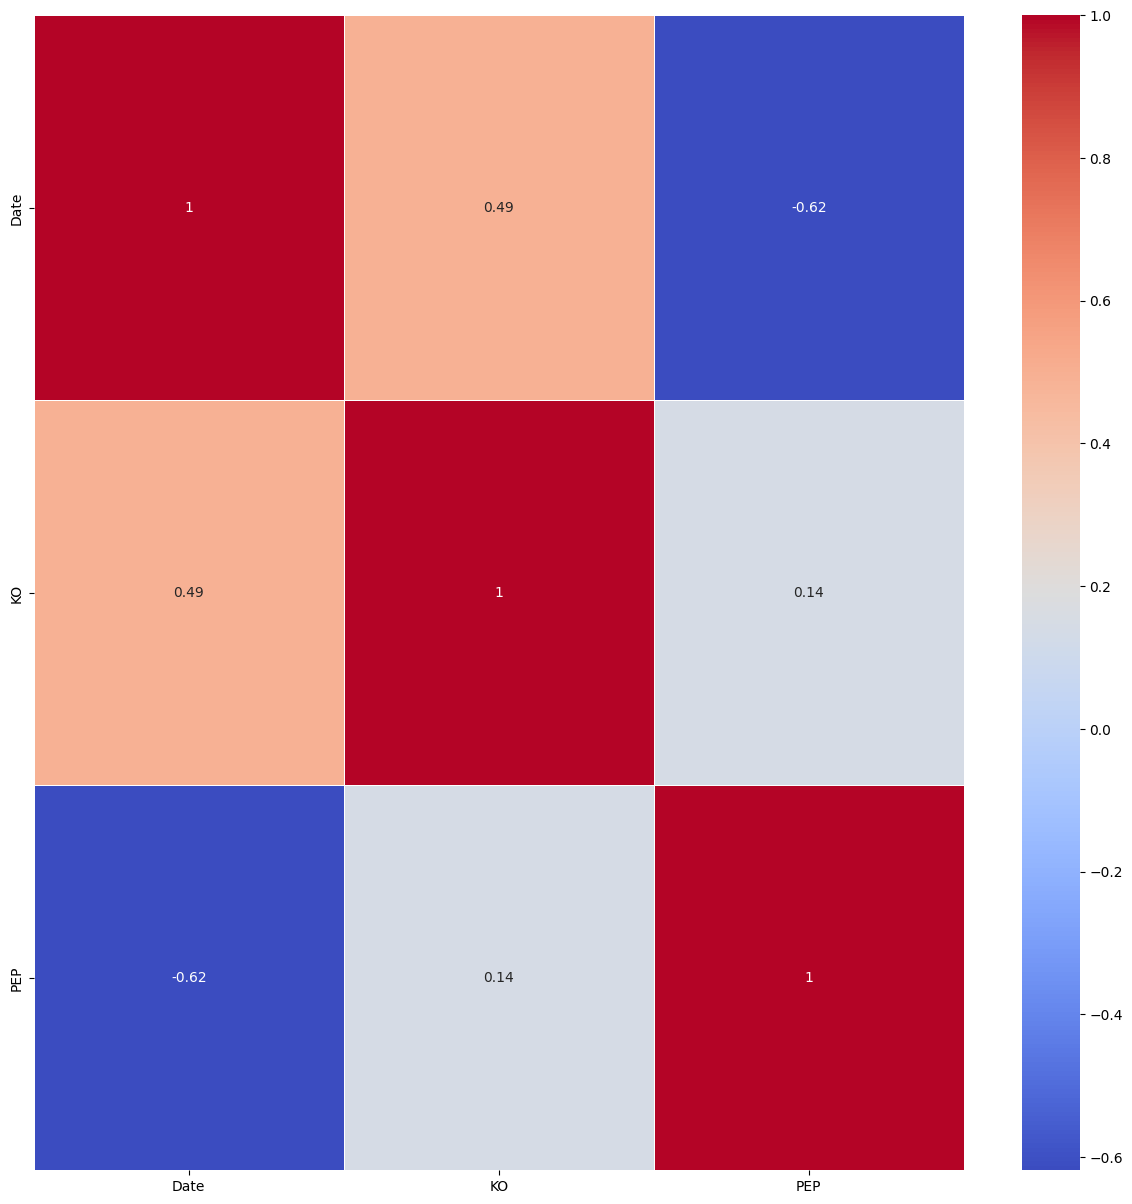

In [10]:
plt.figure(figsize=(15, 15))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', linewidths=0.5)
plt.show()

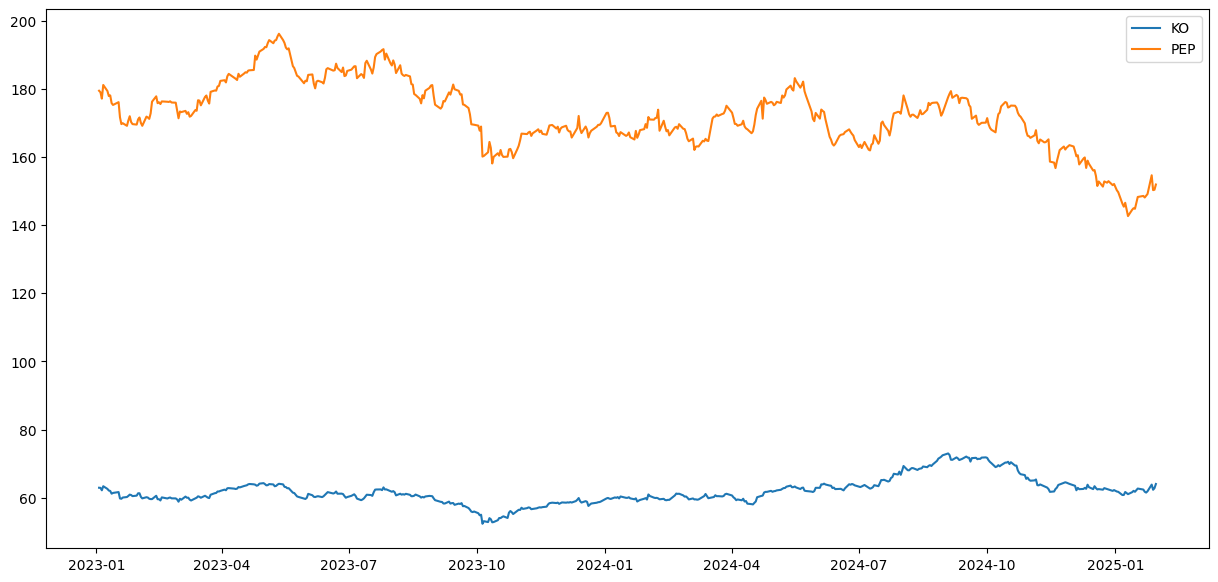

In [11]:
plt.figure(figsize=(15, 7))

plt.plot(df['Date'], df['KO'], label='KO')
plt.plot(df['Date'], df['PEP'], label='PEP')

plt.legend()
plt.show()

In [12]:
import statsmodels.tsa.stattools as ts 

result = ts.coint(df['KO'], df['PEP'])

cointegration_t_statistic = result[0]
p_val = result[1]
critical_values_test_statistic_at_1_5_10 = result[2]

p_val

0.7781058092171831

In [29]:
train_size = int(len(df) * 0.8)

train, test = df[:train_size], df[train_size:]

train

,Date,KO,PEP
0,2022-01-03,180.800003,91.330002
1,2022-01-04,186.979996,94.190002
2,2022-01-05,191.000000,96.239998
3,2022-01-06,189.100006,96.220001
4,2022-01-07,187.740005,95.599998
...,...,...,...
624,2024-06-11,111.199997,91.120003
625,2024-06-12,109.550003,90.260002
626,2024-06-13,105.750000,88.260002
627,2024-06-14,104.500000,86.900002


In [18]:
S1 = train['KO']
S2 = train['PEP']

In [48]:
S1 = sm.add_constant(S1)
results = sm.OLS(S2, S1).fit()
S1 = S1['KO']
b = results.params[1]

spread = S2 - b * S1
b

C:\Users\yanbl\AppData\Local\Temp\ipykernel_26260\1013101246.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  b = results.params[1]


1.5084112112017183

In [20]:
spread

0      30.875555
1      30.165556
2      28.972858
3      30.893397
4      31.849034
         ...    
196    35.094669
197    34.619418
198    35.047404
199    36.316557
200    36.841811
Length: 201, dtype: float64

In [21]:
94.4400  - b * 42.1399 

30.875702401080716

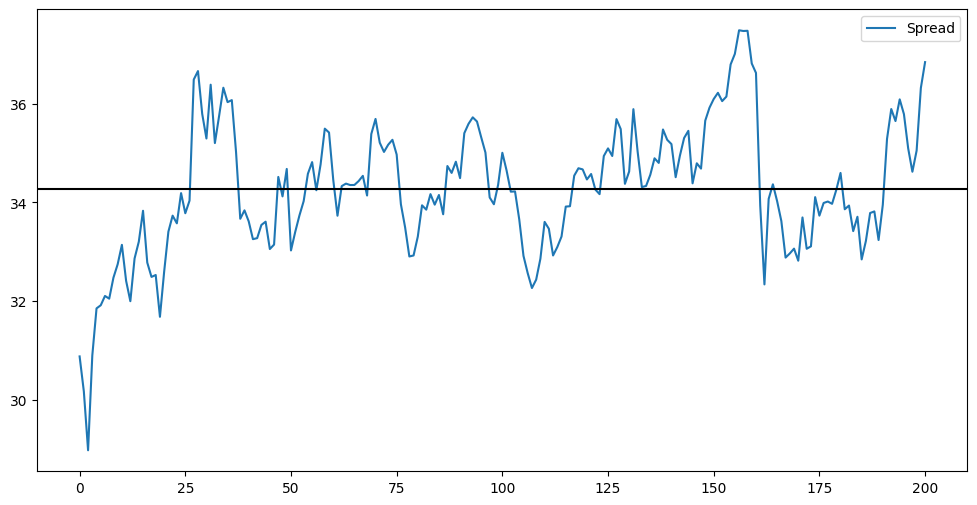

In [22]:
spread.plot(figsize=(12,6))
plt.axhline(spread.mean(), color='black')
#plt.xlim('2015-01-01', '2016-01-01')
plt.legend(['Spread']);

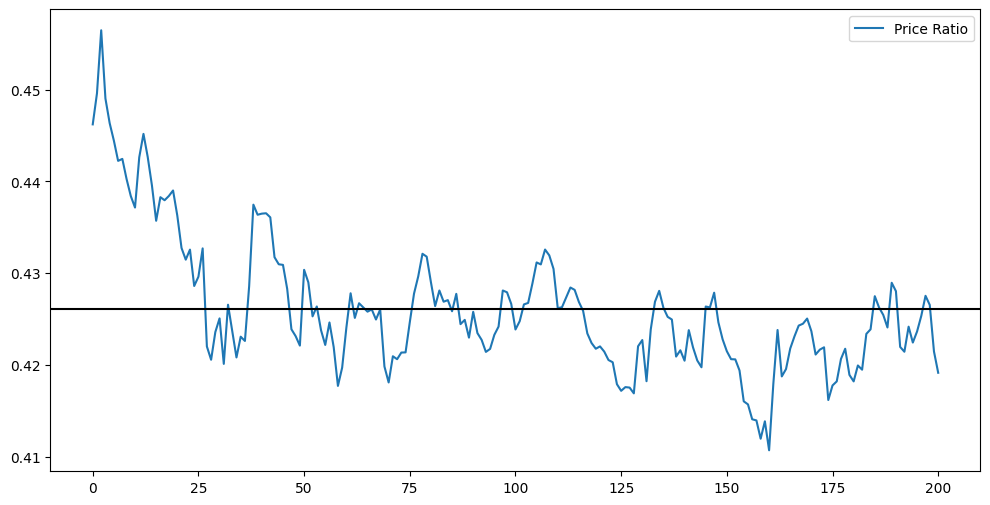

In [23]:
ratio = S1/S2

ratio.plot(figsize=(12,6))
plt.axhline(ratio.mean(), color='black')
#plt.xlim('2015-01-01', '2016-01-01')
plt.legend(['Price Ratio']);

In [47]:
from statsmodels.tsa.stattools import adfuller

KO_ADF = adfuller(train['KO'])
print('P value for the Augmented Dickey-Fuller Test is', KO_ADF[1])

PEP_ADF = adfuller(train['PEP'])
print('P value for the Augmented Dickey-Fuller Test is', PEP_ADF[1])

Spread_ADF = adfuller(spread)
print('P value for the Augmented Dickey-Fuller Test is', Spread_ADF[1])

Ratio_ADF = adfuller(ratio)
print('P value for the Augmented Dickey-Fuller Test is', Ratio_ADF[1])

P value for the Augmented Dickey-Fuller Test is 0.07407800279881005
P value for the Augmented Dickey-Fuller Test is 0.015857316932171264
P value for the Augmented Dickey-Fuller Test is 0.0003903895268780346
P value for the Augmented Dickey-Fuller Test is 0.01026421334945116


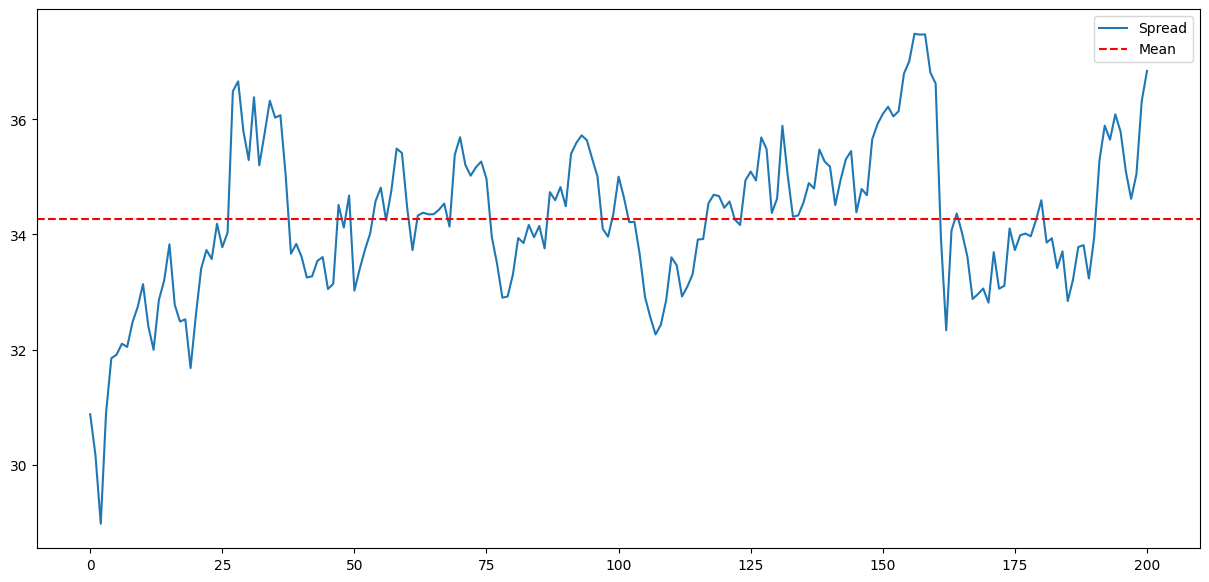

In [35]:
plt.figure(figsize=(15, 7))
plt.plot(spread, label='Spread')
plt.axhline(spread.mean(), color='red', linestyle='--', label='Mean')
plt.legend()

plt.show()

In [36]:
z_score_spread = (spread - spread.mean()) / spread.std()
z_score_spread

0     -2.554825
1     -3.088993
2     -3.986320
3     -2.541401
4     -1.822428
         ...   
196    0.619426
197    0.261871
198    0.583866
199    1.538714
200    1.933889
Length: 201, dtype: float64

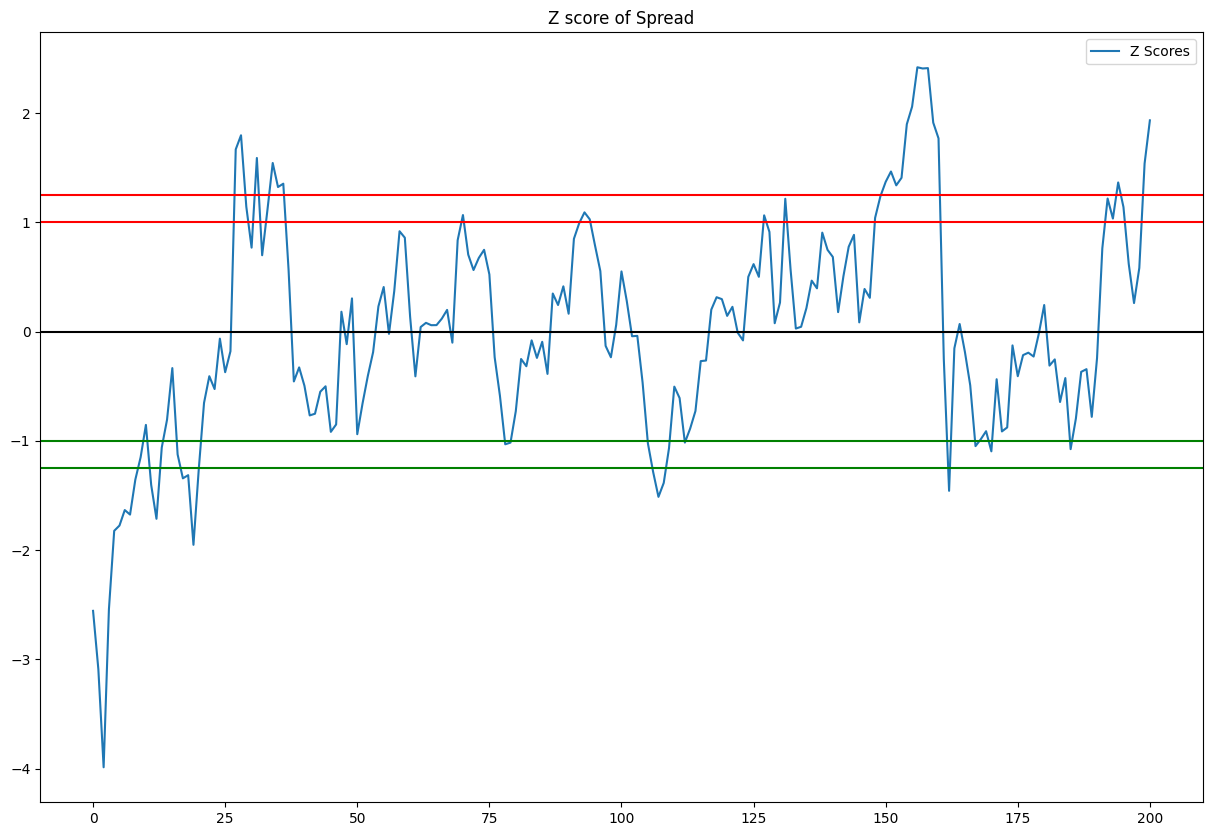

In [37]:
plt.figure(figsize=(15, 10))
# Calculate the Zscores of each row.

plt.plot(z_score_spread, label = "Z Scores")
plt.axhline(z_score_spread.mean(), color = 'black')

plt.axhline(1.0, color='red') # Setting the upper and lower bounds to be the z score of 1 and -1 (1/-1 standard deviation)
plt.axhline(1.25, color='red') # 95% of data will lie between these bounds.
plt.axhline(-1.0, color='green') # 68% of data will lie between these bounds.
plt.axhline(-1.25, color='green') # 95% of data will lie between these bounds.
plt.legend(loc = 'best')
plt.title('Z score of Spread')
plt.show()

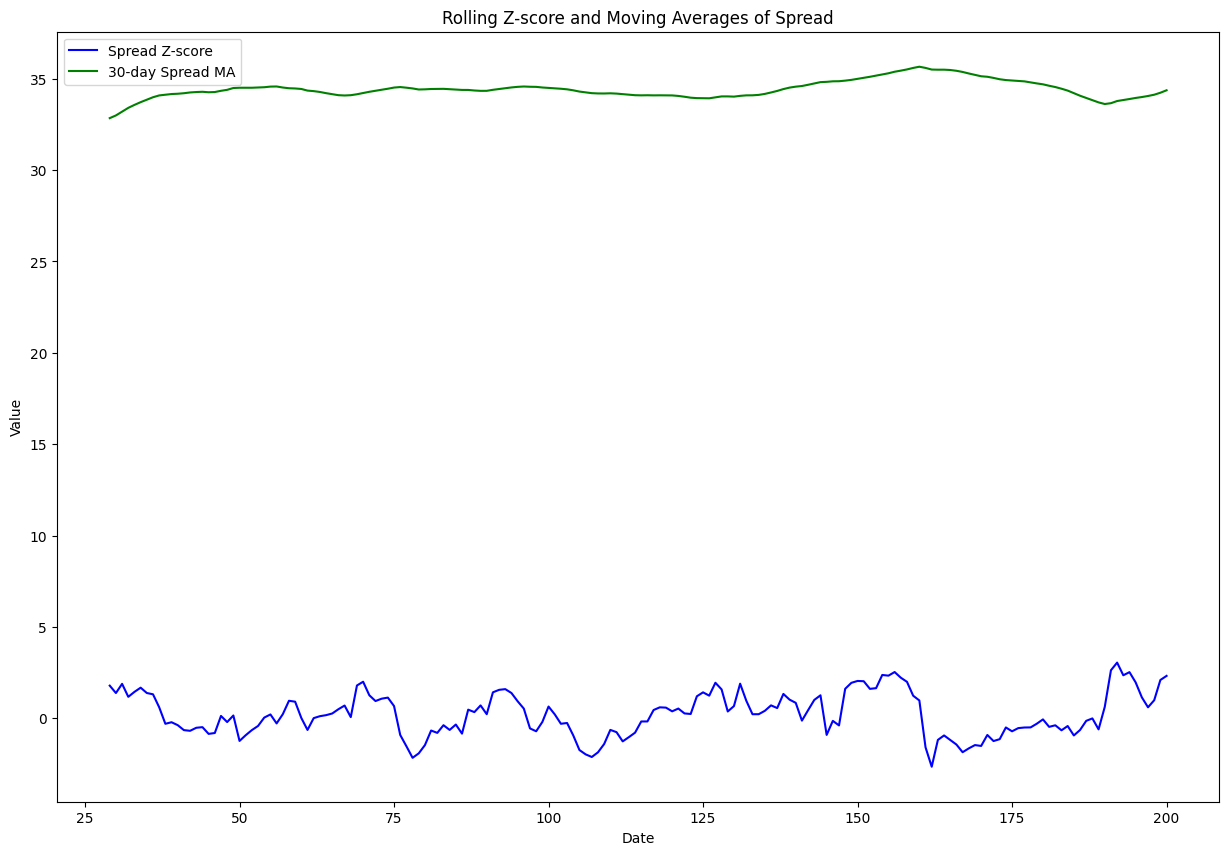

In [49]:
plt.figure(figsize=(15, 10))

window_low = 5
window_high = 30

# Compute rolling means (5-day and 30-day)
#spread_mavg5 = spread.rolling(window_low).mean()
rolling_mean  = spread.rolling(window_high).mean()

# Compute rolling standard deviation (30-day)
rolling_std  = spread.rolling(window=30).std()

# Correct z-score calculation
z_score = (spread - rolling_mean) / rolling_std

# Plot results
plt.plot(z_score.index, z_score.values, label="Spread Z-score", color="blue")
#plt.plot(spread_mavg5.index, spread_mavg5.values, label="5-day Spread MA", color="red")
plt.plot(rolling_mean.index, rolling_mean.values, label="30-day Spread MA", color="green")

plt.legend()
plt.title("Rolling Z-score and Moving Averages of Spread")
plt.xlabel("Date")
plt.ylabel("Value")
plt.show()


In [51]:
# Compute Rolling Z-Score (30-day Window)
rolling_mean = spread.rolling(window=30).mean()
rolling_std = spread.rolling(window=30).std()
z_score = (spread - rolling_mean) / rolling_std

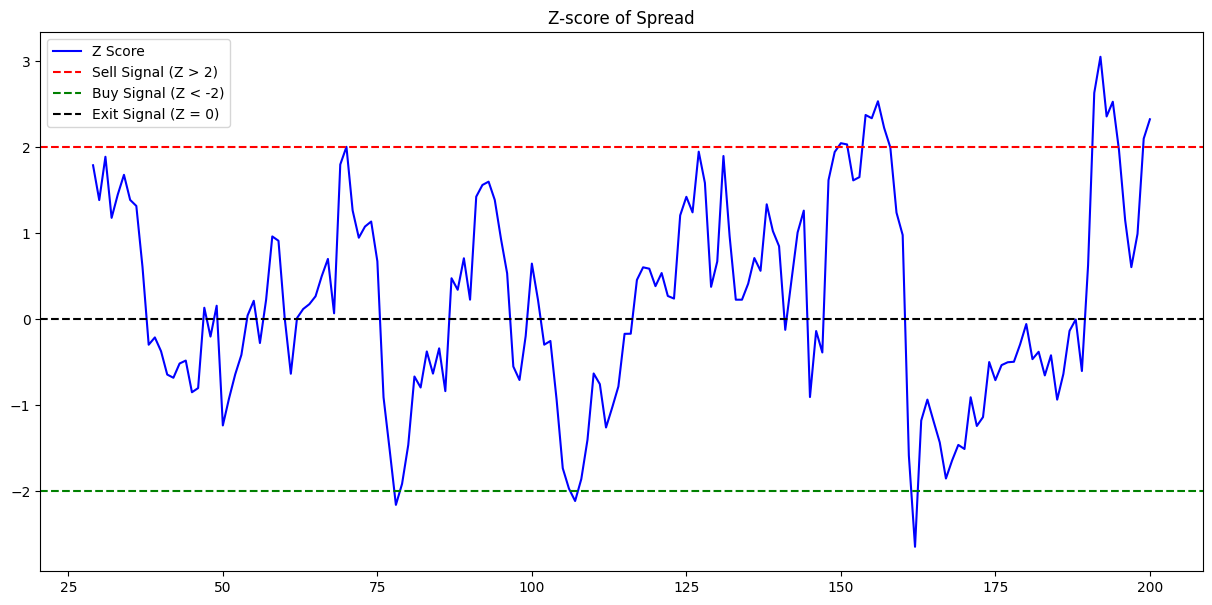

In [50]:
# Plot Z-Score with Correct Thresholds
plt.figure(figsize=(15, 7))
plt.plot(z_score, label="Z Score", color="blue")
plt.axhline(2.0, color='red', linestyle='--', label='Sell Signal (Z > 2)')
plt.axhline(-2.0, color='green', linestyle='--', label='Buy Signal (Z < -2)')
plt.axhline(0.0, color='black', linestyle='--', label='Exit Signal (Z = 0)')
plt.legend()
plt.title('Z-score of Spread')
plt.show()

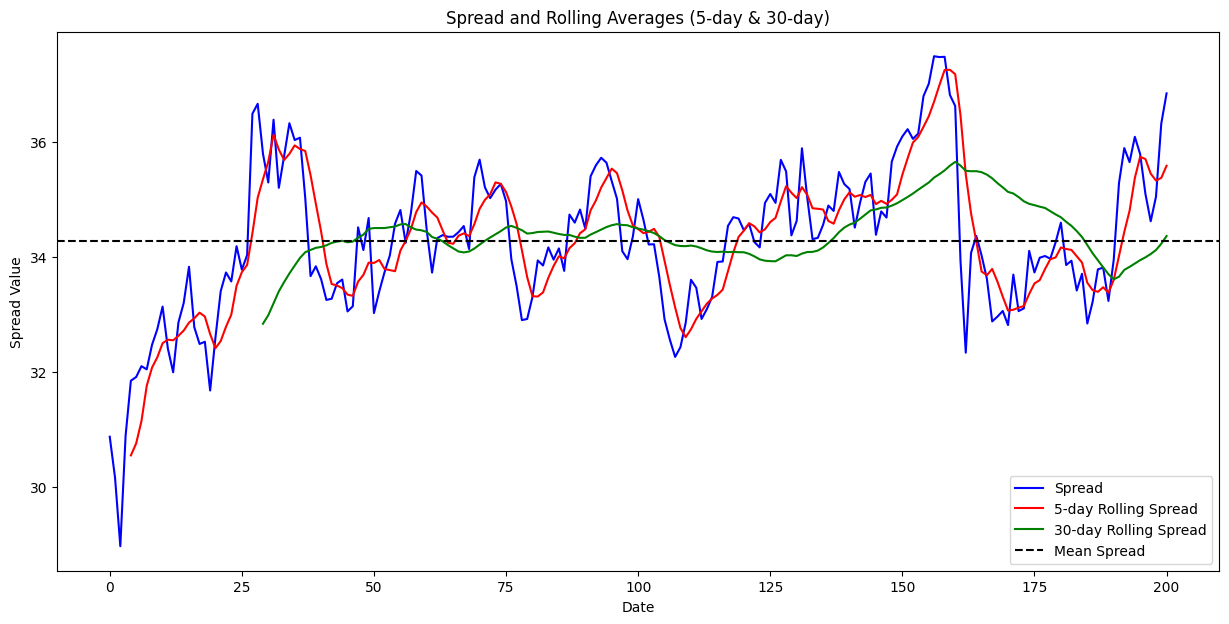

In [52]:
plt.figure(figsize=(15, 7))

# Compute Rolling Means
spread_mavg5 = spread.rolling(window=5).mean()
spread_mavg30 = spread.rolling(window=30).mean()

# Plot Original Spread
plt.plot(spread.index, spread.values, label="Spread", color="blue")

# Plot Rolling Averages
plt.plot(spread_mavg5.index, spread_mavg5.values, label="5-day Rolling Spread", color="red")
plt.plot(spread_mavg30.index, spread_mavg30.values, label="30-day Rolling Spread", color="green")

# Add Mean Line
plt.axhline(spread.mean(), color='black', linestyle='--', label="Mean Spread")

# Formatting
plt.legend()
plt.title("Spread and Rolling Averages (5-day & 30-day)")
plt.xlabel("Date")
plt.ylabel("Spread Value")
plt.show()


Test Data

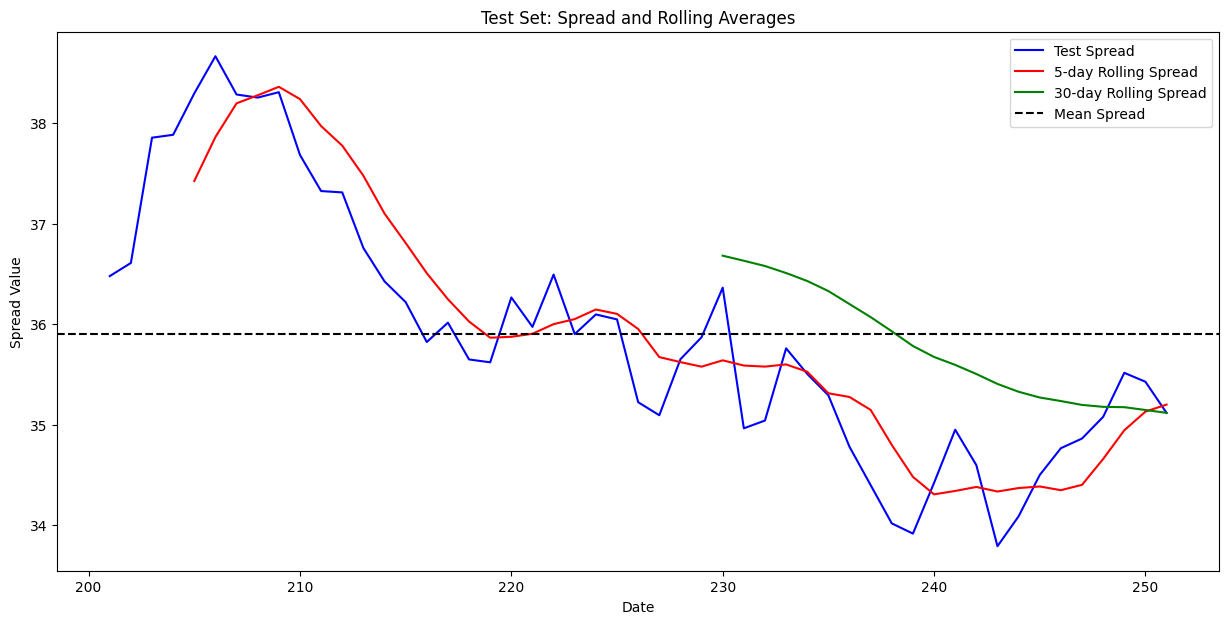

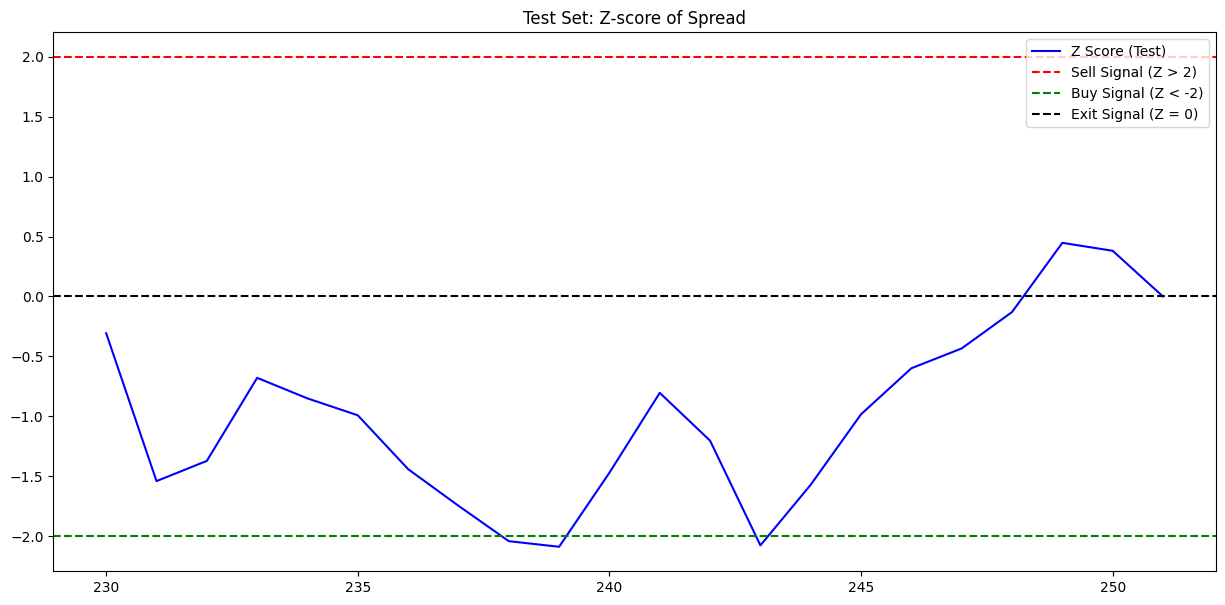

In [53]:
# Use the trained hedge ratio (b) on the test set
S1_test = test['KO']
S2_test = test['PEP']

# Compute the spread for the test set
spread_test = S2_test - b * S1_test

# Compute rolling mean and rolling std on test spread
rolling_mean_test = spread_test.rolling(window=30).mean()
rolling_std_test = spread_test.rolling(window=30).std()

# Compute Z-score for test data
z_score_test = (spread_test - rolling_mean_test) / rolling_std_test

# Plot the test set spread and rolling spread
plt.figure(figsize=(15, 7))

# Original spread
plt.plot(spread_test.index, spread_test.values, label="Test Spread", color="blue")

# Rolling Means (5-day and 30-day)
plt.plot(spread_test.rolling(window=5).mean(), label="5-day Rolling Spread", color="red")
plt.plot(spread_test.rolling(window=30).mean(), label="30-day Rolling Spread", color="green")

# Mean Line
plt.axhline(spread_test.mean(), color='black', linestyle='--', label="Mean Spread")

# Formatting
plt.legend()
plt.title("Test Set: Spread and Rolling Averages")
plt.xlabel("Date")
plt.ylabel("Spread Value")
plt.show()

# Plot the Z-score for the test period
plt.figure(figsize=(15, 7))
plt.plot(z_score_test, label="Z Score (Test)", color="blue")
plt.axhline(2.0, color='red', linestyle='--', label='Sell Signal (Z > 2)')
plt.axhline(-2.0, color='green', linestyle='--', label='Buy Signal (Z < -2)')
plt.axhline(0.0, color='black', linestyle='--', label='Exit Signal (Z = 0)')
plt.legend()
plt.title("Test Set: Z-score of Spread")
plt.show()


In [54]:
Spread_Test_ADF = adfuller(spread_test)
print('P value for the Augmented Dickey-Fuller Test is', Spread_Test_ADF[1])

P value for the Augmented Dickey-Fuller Test is 0.6471971875068375


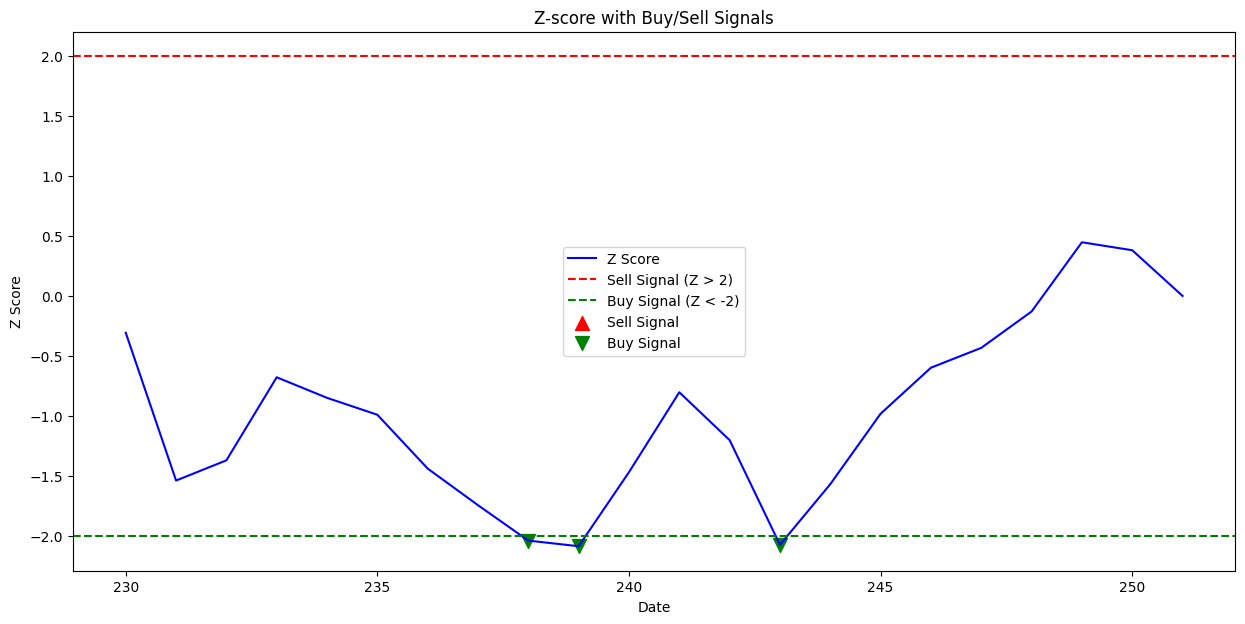

In [55]:
plt.figure(figsize=(15, 7))

# Plot the Z-score
plt.plot(z_score_test, label="Z Score", color="blue")

# Add horizontal lines for buy/sell signals
plt.axhline(2.0, color='red', linestyle='--', label="Sell Signal (Z > 2)")
plt.axhline(-2.0, color='green', linestyle='--', label="Buy Signal (Z < -2)")

# Add triangles for Buy/Sell points (for Z > 2 or Z < -2)
plt.scatter(z_score_test.index[z_score_test > 2], z_score_test[z_score_test > 2], 
            marker='^', color='red', label="Sell Signal", s=100)  # Sell signal
plt.scatter(z_score_test.index[z_score_test < -2], z_score_test[z_score_test < -2], 
            marker='v', color='green', label="Buy Signal", s=100)  # Buy signal

# Formatting
plt.title("Z-score with Buy/Sell Signals")
plt.xlabel("Date")
plt.ylabel("Z Score")
plt.legend()
plt.show()


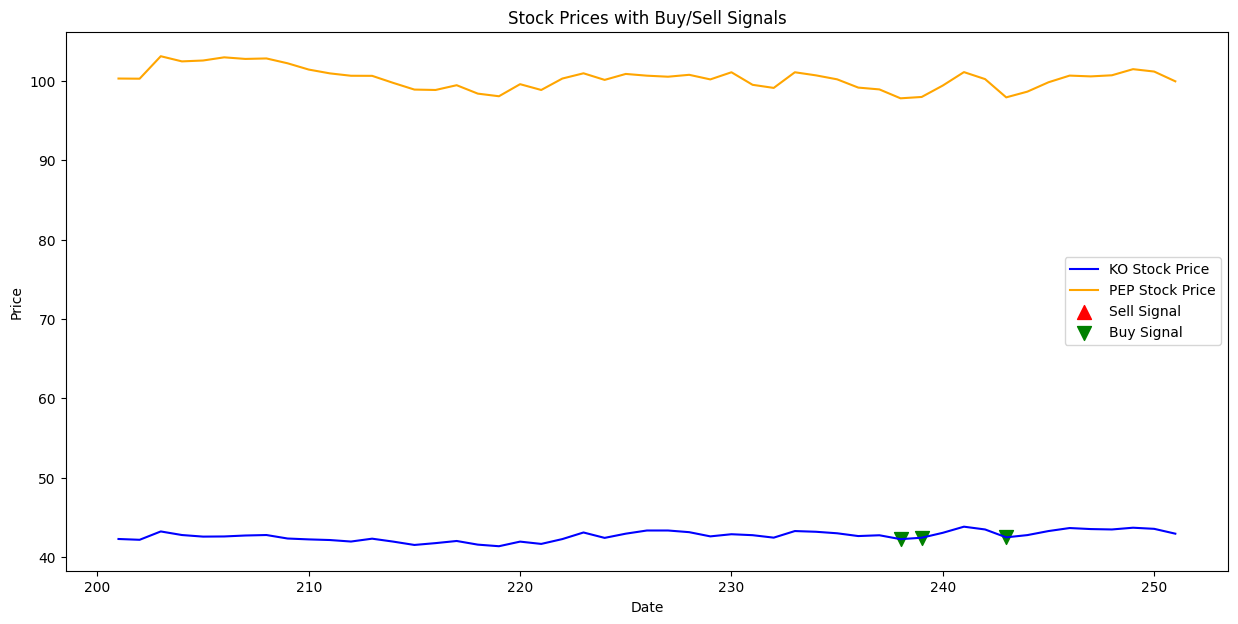

In [59]:
plt.figure(figsize=(15, 7))

# Plot the two stocks
plt.plot(test['KO'], label="KO Stock Price", color="blue")
plt.plot(test['PEP'], label="PEP Stock Price", color="orange")

# Add triangles for Buy/Sell points
plt.scatter(test.index[z_score_test > 2], test['KO'][z_score_test > 2], 
            marker='^', color='red', label="Sell Signal", s=100)  # Sell signal
plt.scatter(test.index[z_score_test < -2], test['KO'][z_score_test < -2], 
            marker='v', color='green', label="Buy Signal", s=100)  # Buy signal

# Formatting
plt.title("Stock Prices with Buy/Sell Signals")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()


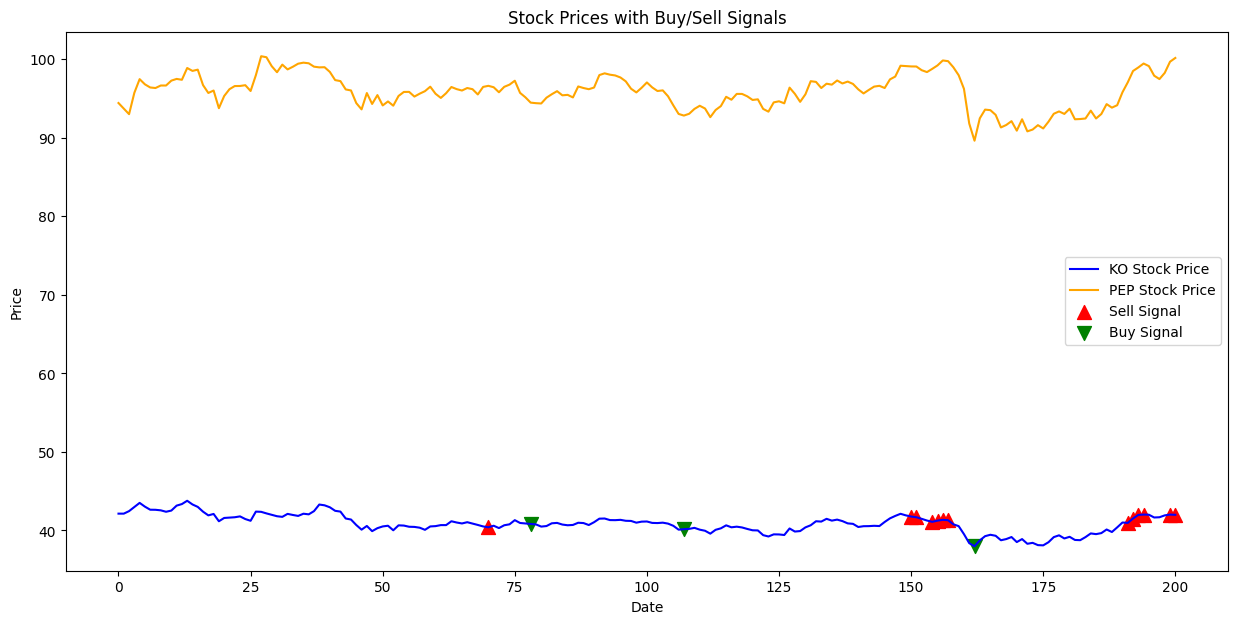

In [58]:
plt.figure(figsize=(15, 7))

# Plot the two stocks
plt.plot(train['KO'], label="KO Stock Price", color="blue")
plt.plot(train['PEP'], label="PEP Stock Price", color="orange")

# Add triangles for Buy/Sell points
plt.scatter(train.index[z_score > 2], train['KO'][z_score > 2], 
            marker='^', color='red', label="Sell Signal", s=100)  # Sell signal
plt.scatter(train.index[z_score < -2], train['KO'][z_score < -2], 
            marker='v', color='green', label="Buy Signal", s=100)  # Buy signal

# Formatting
plt.title("Stock Prices with Buy/Sell Signals")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()


In [28]:
z_score_ratio = (ratio - ratio.mean()) / ratio.std()
z_score_ratio

0      2.833241
1      3.307321
2      4.271153
3      3.228694
4      2.852698
         ...   
247    0.989141
248    0.835023
249    0.679331
250    0.664430
251    0.551878
Length: 252, dtype: float64

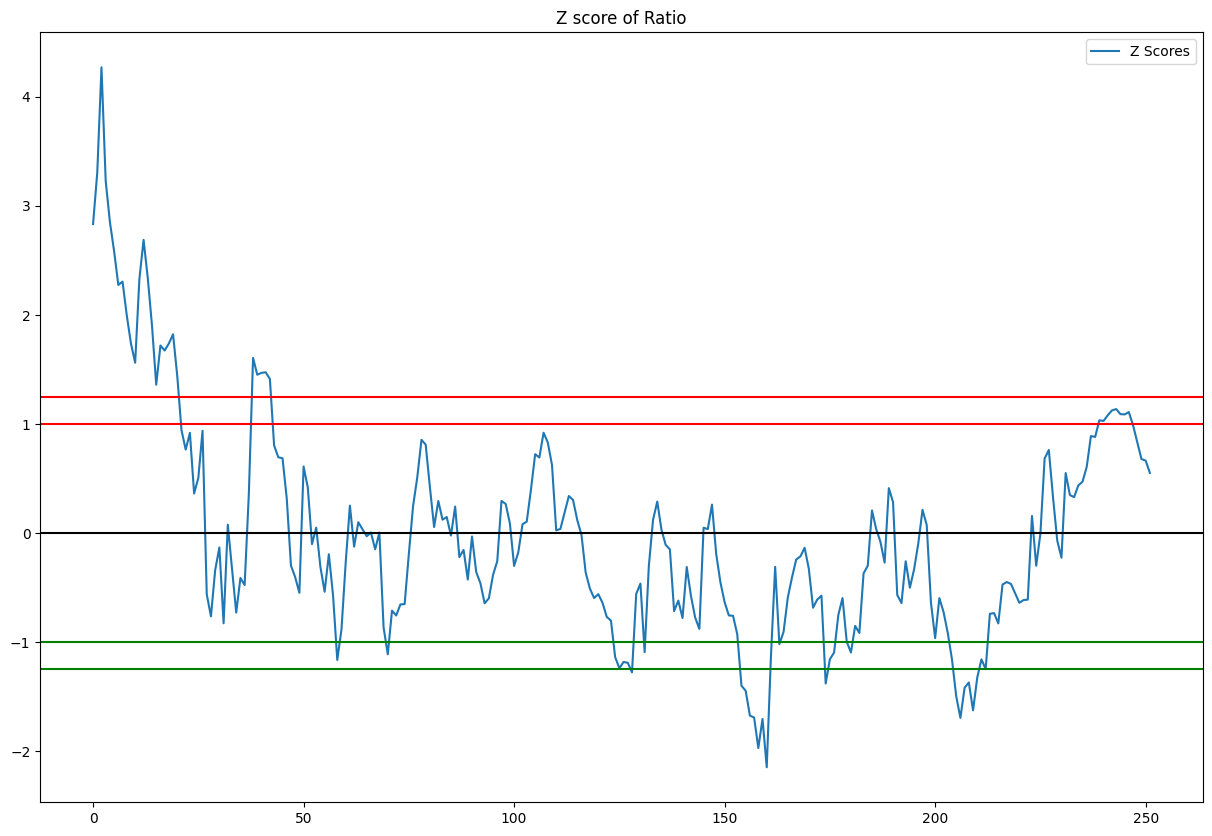

In [29]:
plt.figure(figsize=(15, 10))
# Calculate the Zscores of each row.

plt.plot(z_score_ratio, label = "Z Scores")
plt.axhline(z_score_ratio.mean(), color = 'black')

plt.axhline(1.0, color='red') # Setting the upper and lower bounds to be the z score of 1 and -1 (1/-1 standard deviation)
plt.axhline(1.25, color='red') # 95% of data will lie between these bounds.
plt.axhline(-1.0, color='green') # 68% of data will lie between these bounds.
plt.axhline(-1.25, color='green') # 95% of data will lie between these bounds.
plt.legend(loc = 'best')
plt.title('Z score of Ratio')
plt.show()

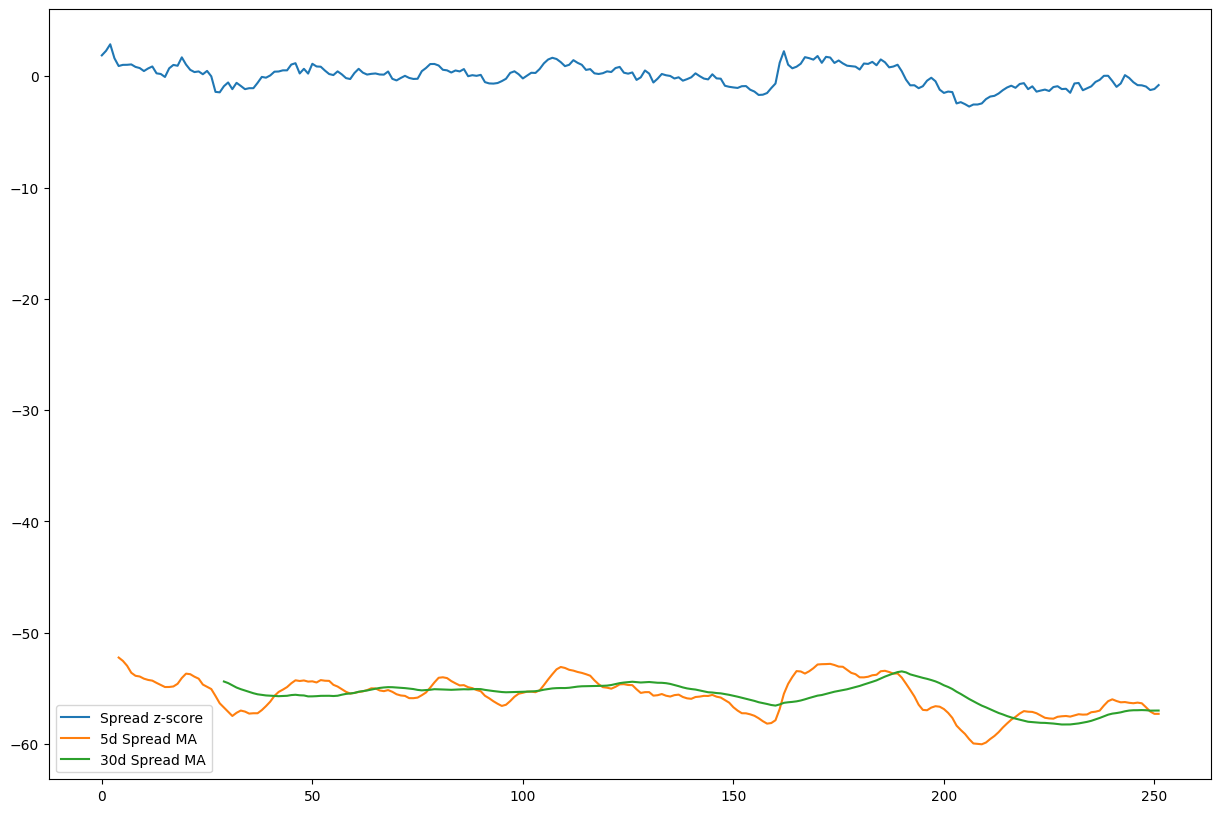

In [39]:
plt.figure(figsize = (15, 10))

spread_mavg5 = spread.rolling(window=5, center=False).mean()
spread_mavg30 = spread.rolling(window=30, center=False).mean()

std_30 = spread.rolling(window=30, center=False).std()
z_score_30_5 = (spread_mavg5 - spread_mavg30)/std_30

plt.plot(z_score.index, z_score.values)
plt.plot(spread_mavg5.index, spread_mavg5.values)
plt.plot(spread_mavg30.index, spread_mavg30.values)
plt.legend(['Spread z-score', '5d Spread MA', '30d Spread MA'])

plt.show()

TypeError: axis() takes from 0 to 1 positional arguments but 4 were given

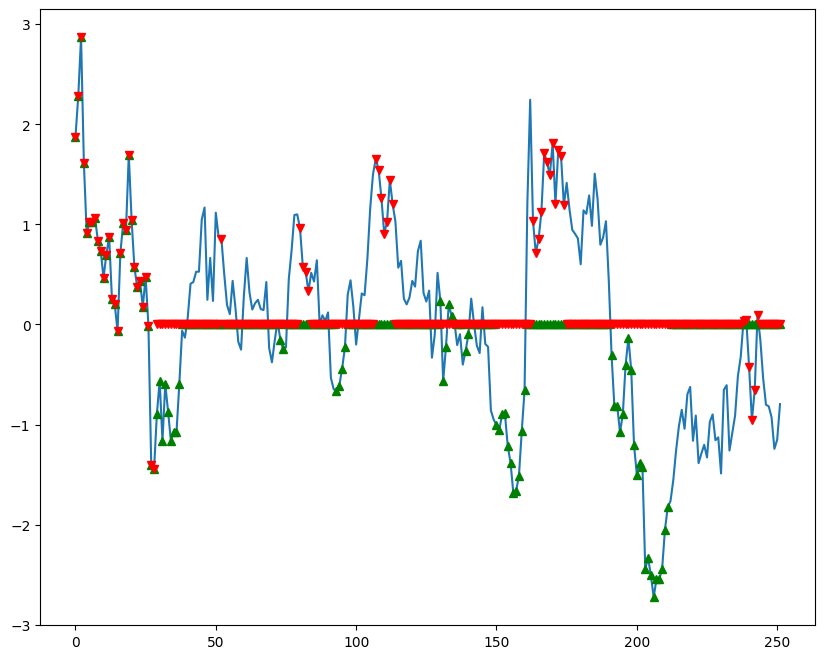

In [43]:
plt.figure(figsize=(10, 8))
plt.plot(z_score)

buy = z_score.copy()
sell = z_score.copy()

buy[z_score_30_5 > -1] = 0
sell[z_score_30_5 < 1] = 0

plt.plot(buy, color='g', linestyle='None', marker='^')
plt.plot(sell, color='r', linestyle='None', marker='v')

x1, x2, y1, y2 = plt.axis()
plt.axis(x1, x2, z_score.min(), z_score.max())
plt.legend(['Spread z-score', 'Buy Signal', 'Sell Signal'])
plt.title('Buy and Sell Signals')

plt.show()

In [47]:
# Compute rolling mean and rolling standard deviation
def calc_zscore(ratios, window1, window2):
    ma1 = ratios.rolling(window=window1,center=False).mean()
    ma2 = ratios.rolling(window=window2,center=False).mean()
    std = ratios.rolling(window=window2,center=False).std()
    zscore = (ma1 - ma2)/std
    return zscore

def plot_explain(S1, S2, window1, window2, zscore_60_5, gold_marker_gain, gold_marker_loss):
    ratio = S1 / S2
    # Plot price buy sell
    plt.figure(figsize=(18,9))
    buy = ratio.copy()
    sell = ratio.copy()
    buy[zscore_60_5>-1] = 0
    sell[zscore_60_5<1] = 0
    # Init buyR and sellR
    S1[window2:].plot(color='b')
    S2[window2:].plot(color='c')
    buyR = 0*S1.copy()
    sellR = 0*S1.copy()
    # When buying the ratio, buy S1 and sell S2
    buyR[buy!=0] = S1[buy!=0]
    sellR[buy!=0] = S2[buy!=0]
    # When selling the ratio, sell S1 and buy S2 
    buyR[sell!=0] = S2[sell!=0]
    sellR[sell!=0] = S1[sell!=0]
    # Plot buy and sell
    buyR[window2:].plot(color='g', linestyle='None', marker='^')
    sellR[window2:].plot(color='r', linestyle='None', marker='^')
    x1,x2,y1,y2 = plt.axis()
    plt.axis( (x1, x2, min(S1.min(),S2.min()), max(S1.max(),S2.max()) ) )
    plt.legend(['KO','PEP', 'Buy Signal', 'Sell Signal'])
    plt.show()
    # plot zscore
    plt.figure(figsize=(18,7))
    zscore_60_5.plot()
    plt.axhline(0, color='black')
    plt.axhline(1.0, color='red', linestyle='--')
    plt.axhline(-1.0, color='green', linestyle='--')
    gold_marker_gain.plot(color='g', linestyle='None', marker='^')
    gold_marker_loss.plot(color='r', linestyle='None', marker='^')
    plt.legend(['Rolling Ratio z-Score', 'Mean', '+1', '-1'])
    plt.show()

def trade(S1, S2, window1, window2, zthreshhold_buysell=1.0, zthreshhold_clear=0.5, doplot=False):
    maximum_S1_needed = 0
    maximum_S2_needed = 0
    # If window length is 0, algorithm doesn't make sense, so exit
    if (window1 == 0) or (window2 == 0):
        return 0
    ratios = S1/S2
    zscore = calc_zscore(ratios, window1, window2)
    # Simulate trading
    money = 0
    countS1 = 0
    countS2 = 0
    gain_count = 0
    gain_amount = 0.0
    loss_count = 0
    loss_amount = 0.0
    gold_marker_gain = zscore.copy()
    gold_marker_gain[:] = float('nan')
    gold_marker_loss = zscore.copy()
    gold_marker_loss[:] = float('nan')
    for i in range(len(ratios)):
        # Sell short if the z-score is > 1
        if zscore[i] > zthreshhold_buysell:
            tmp = S1[i] - S2[i] * ratios[i]
            money += tmp
            countS1 -= 1
            countS2 += ratios[i]
        # Buy long if the z-score is < 1
        elif zscore[i] < -zthreshhold_buysell:
            tmp = S2[i] * ratios[i] - S1[i]
            money += tmp
            countS1 += 1
            countS2 -= ratios[i]
        # Clear positions if the z-score between -.5 and .5
        elif abs(zscore[i]) < zthreshhold_clear:
            tmp = countS1*S1[i] + S2[i] * countS2
            if maximum_S1_needed < countS1:
                maximum_S1_needed = countS1
            if maximum_S2_needed < countS2:
                maximum_S2_needed = countS2
            if tmp > 0:
                gain_count += 1
                gain_amount += tmp
                gold_marker_gain[i] = zscore[i]
            elif tmp < 0:
                loss_count += 1
                loss_amount += tmp
                gold_marker_loss[i] = zscore[i]
            money += tmp
            countS1 = 0
            countS2 = 0
    tmp = countS1*S1[i] + S2[i] * countS2
    if tmp > 0:
        gain_count += 1
        gain_amount += tmp
    else:
        loss_count += 1
        loss_amount += tmp
    money += tmp
    # plot
    if doplot:
        plot_explain(S1, S2, window1, window2, zscore, gold_marker_gain, gold_marker_loss)
    print(countS1)
    print(countS2)
    print(gain_count)
    print(loss_count)
    print(gain_amount)
    print(loss_amount)
    print("maximum_S1_needed: %f" % maximum_S1_needed)
    print("maximum_S2_needed: %f" % maximum_S2_needed)
    print("Money that is gained addtionally from buy/sell: %f" % money)
    return money

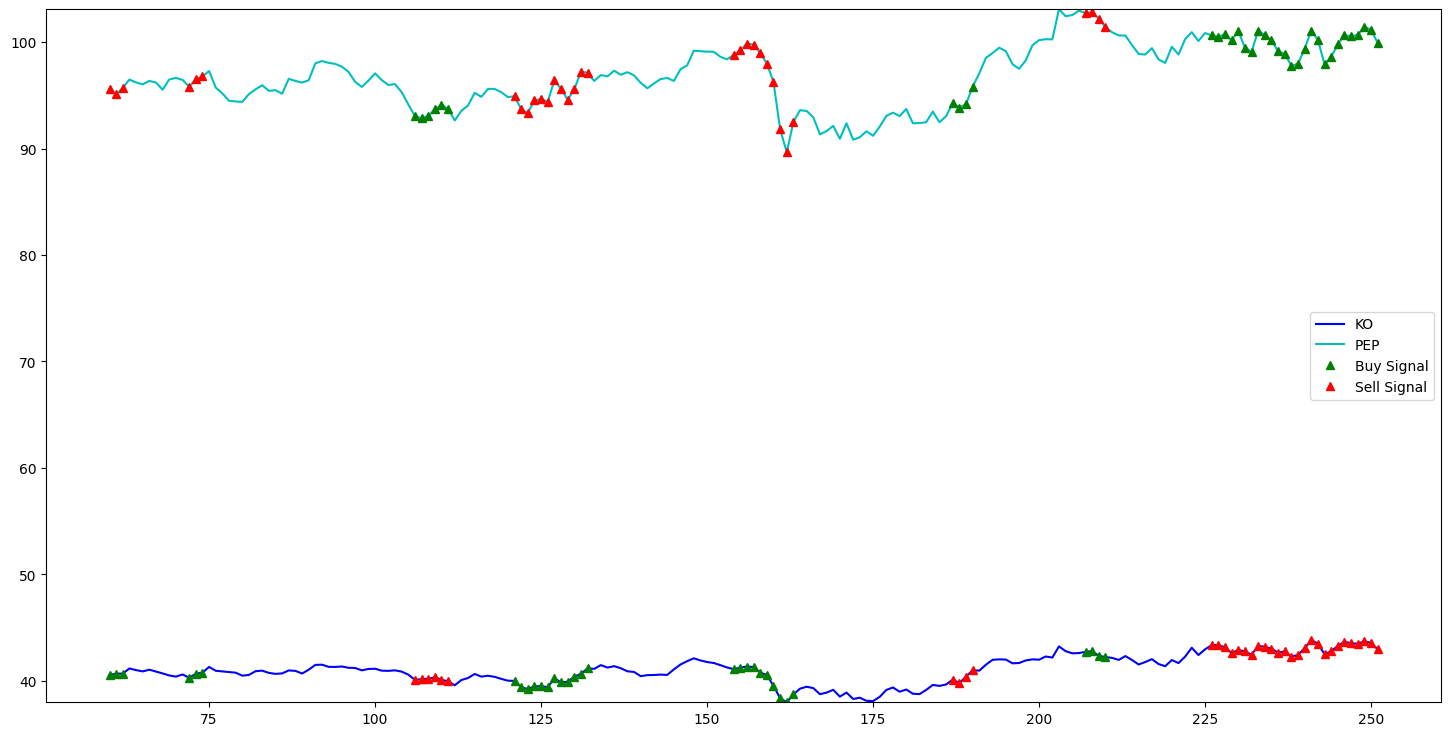

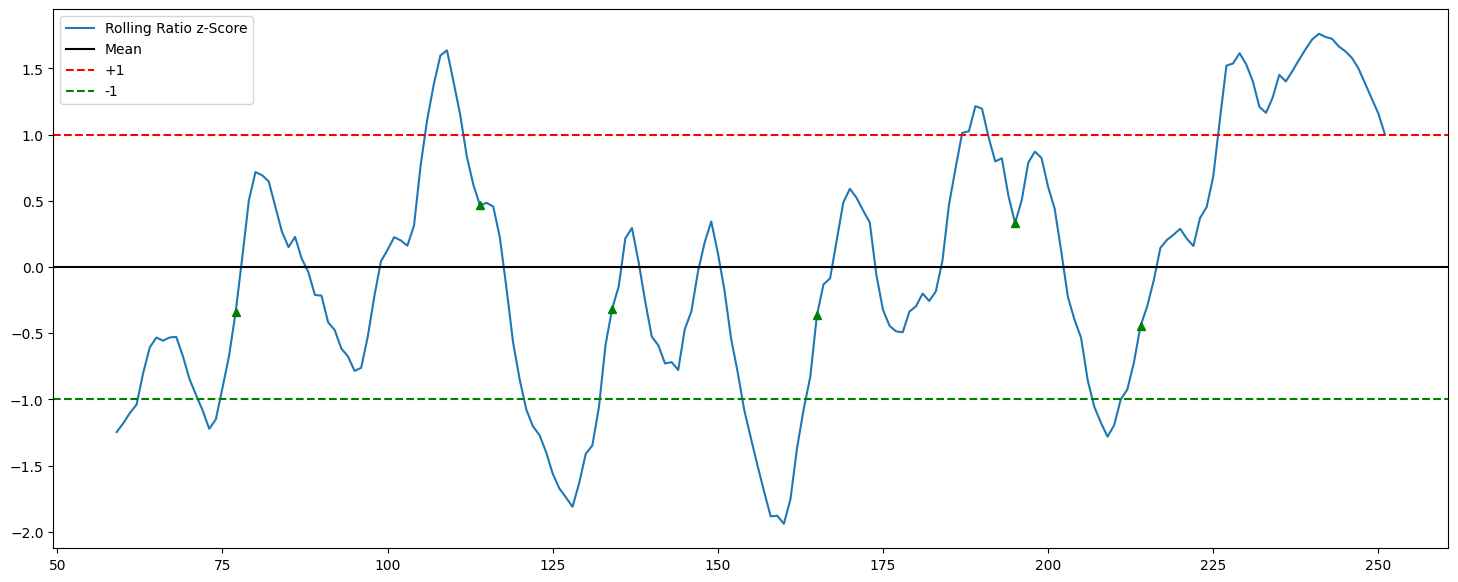

-26
11.207501200017997
7
0
26.935957850405288
0.0
maximum_S1_needed: 12.000000
maximum_S2_needed: 2.578392
Money that is gained addtionally from buy/sell: 26.935958


26.935957850405288

In [48]:
# extra money earned from pair trading 
trade(df['KO'] , df['PEP'], 5, 60, zthreshhold_buysell=1.0, doplot=True)

In [49]:
import numpy as np

In [50]:
def calculate_profit(signals_df, prices, initial_capital=100):
    """
    Calculate the profit from the trading strategy.
    
    Parameters:
    - signals_df (pandas.DataFrame): DataFrame containing the 'orders' column with buy (1) and sell (-1) signals.
    - prices (pandas.Series): Closing prices of the traded asset.
    - initial_capital (float): Starting capital for the strategy.
    
    Returns:
    - profit_df (pandas.DataFrame): DataFrame with cumulative profit over time.
    """
    capital = initial_capital
    position = 0
    profit_history = []

    for date, order in signals_df['orders'].dropna().items():
        price = prices.loc[date]

        if order == 1:  # Buy signal
            position = capital / price  # Buy as many units as possible
            capital = 0
        elif order == -1 and position > 0:  # Sell signal
            capital = position * price  # Sell all units
            position = 0

        profit_history.append(capital + (position * price))  # Track profit over time

    profit_df = pd.DataFrame(index=signals_df.dropna().index, data={'Profit': profit_history})
    return profit_df


In [51]:
def plot_strategy(prices, signals_df, profit_df):
    """
    Plot the trading strategy including buy/sell signals and cumulative profit.

    Parameters:
    - prices (pandas.Series): Closing prices of the traded asset.
    - signals_df (pandas.DataFrame): DataFrame with trading signals.
    - profit_df (pandas.DataFrame): DataFrame with cumulative profit.

    Returns:
    - ax1, ax2 (matplotlib.axes.Axes): Axes of the plots.
    """
    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Plot price series
    ax1.plot(prices, label='Price', color='black')

    # Plot buy signals
    buy_signals = signals_df.loc[signals_df['orders'] == 1]
    ax1.scatter(buy_signals.index, prices.loc[buy_signals.index], marker='^', color='green', label='Buy Signal', alpha=1)

    # Plot sell signals
    sell_signals = signals_df.loc[signals_df['orders'] == -1]
    ax1.scatter(sell_signals.index, prices.loc[sell_signals.index], marker='v', color='red', label='Sell Signal', alpha=1)

    ax1.set_ylabel("Price")
    ax1.legend()
    
    # Create secondary y-axis for profit plot
    ax2 = ax1.twinx()
    ax2.plot(profit_df.index, profit_df['Profit'], label='Cumulative Profit', color='blue', linestyle='dashed', alpha=0.7)
    ax2.set_ylabel("Cumulative Profit")
    ax2.legend(loc='upper right')

    plt.title("Pair Trading Strategy")
    return ax1, ax2


"\nax1.legend(loc='upper left', fontsize=10)\nax1.set_title(f'Citigroup Paired with Aave', fontsize=18)\nax2.legend(loc='upper left', fontsize=10)\nax2.set_title(f'Aave Paired with Citigroup', fontsize=18)\nplt.tight_layout()\nplt.show() "

<Figure size 2600x1800 with 0 Axes>

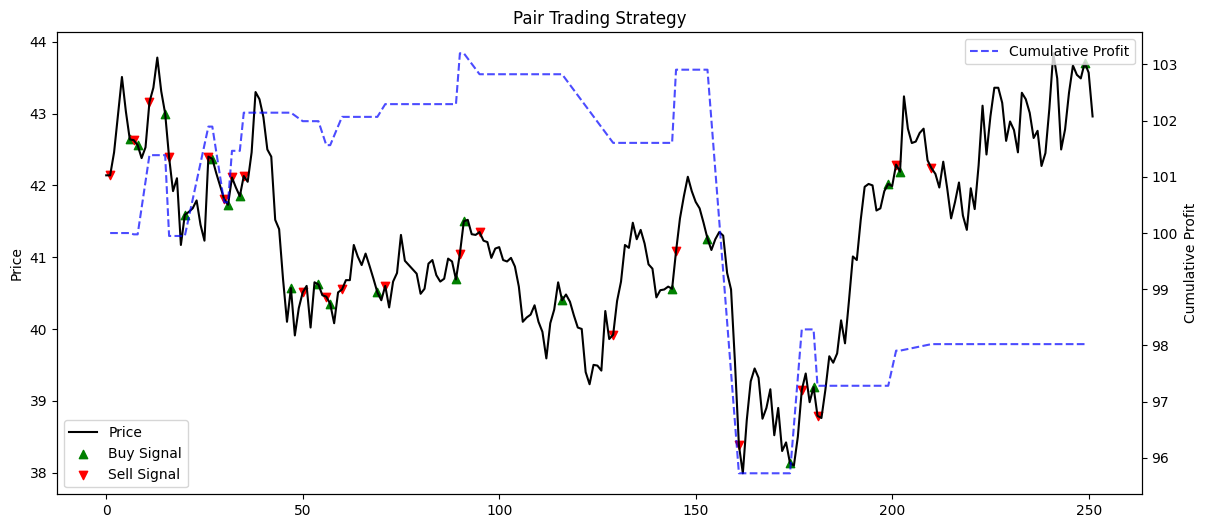

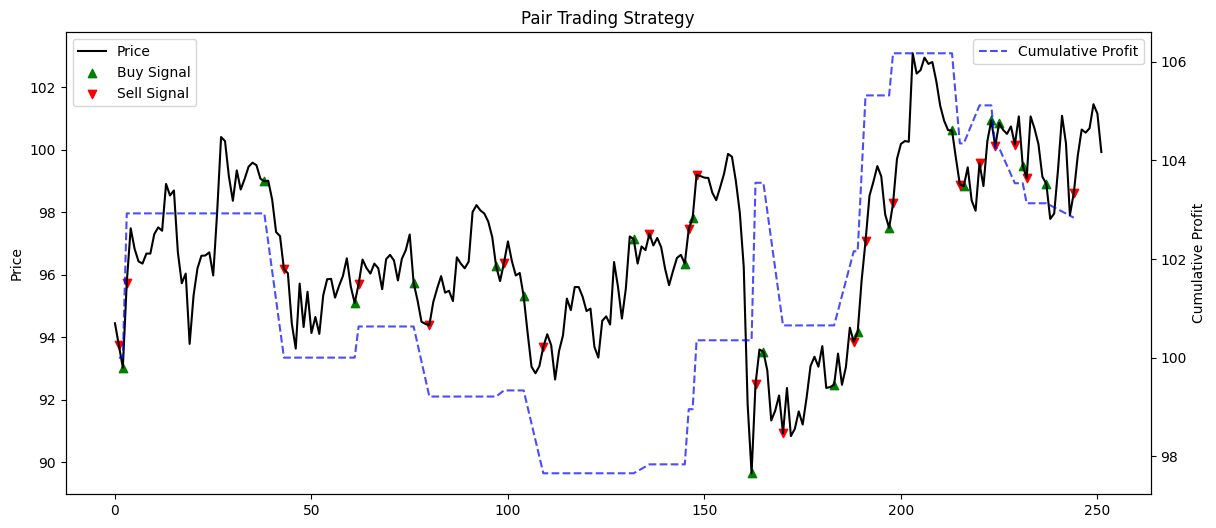

In [56]:
def signals_zscore_evolution(ticker1_ts, ticker2_ts, window_size=15, first_ticker=True):
    """
    Generate trading signals based on z-score analysis of the ratio between two time series.
    Parameters:
    - ticker1_ts (pandas.Series): Time series data for the first security.
    - ticker2_ts (pandas.Series): Time series data for the second security.
    - window_size (int): The window size for calculating z-scores and ratios' statistics.
    - first_ticker (bool): Set to True to use the first ticker as the primary signal source, and False to use the second.

    Returns:
    - signals_df (pandas.DataFrame): A DataFrame with 'signal' and 'orders' columns containing buy (1) and sell (-1) signals.

    """
    ratios = ticker1_ts / ticker2_ts

    ratios_mean = ratios.rolling(
        window=window_size, min_periods=1, center=False).mean()
    ratios_std = ratios.rolling(
        window=window_size, min_periods=1, center=False).std()

    z_scores = (ratios - ratios_mean) / ratios_std

    buy = ratios.copy()
    sell = ratios.copy()

    if first_ticker:
        # These are empty zones, where there should be no signal
        # the rest is signalled by the ratio.
        buy[z_scores > -1] = 0
        sell[z_scores < 1] = 0
    else:
        buy[z_scores < 1] = 0
        sell[z_scores > -1] = 0

    signals_df = pd.DataFrame(index=ticker1_ts.index)
    signals_df['signal'] = np.where(buy > 0, 1, np.where(sell < 0, -1, 0))
    signals_df['orders'] = signals_df['signal'].diff()
    signals_df.loc[signals_df['orders'] == 0, 'orders'] = None

    return signals_df


plt.figure(figsize=(26, 18))
signals_df1 = signals_zscore_evolution(df['KO'], df['PEP'])
profit_df1 = calculate_profit(signals_df1, df['KO'])
ax1, _ = plot_strategy(df['KO'], signals_df1, profit_df1)

signals_df2 = signals_zscore_evolution(df['KO'], df['PEP'], first_ticker=False)
profit_df2 = calculate_profit(signals_df2, df['PEP'])
ax2, _ = plot_strategy(df['PEP'], signals_df2, profit_df2)

'''
ax1.legend(loc='upper left', fontsize=10)
ax1.set_title(f'Citigroup Paired with Aave', fontsize=18)
ax2.legend(loc='upper left', fontsize=10)
ax2.set_title(f'Aave Paired with Citigroup', fontsize=18)
plt.tight_layout()
plt.show() '''

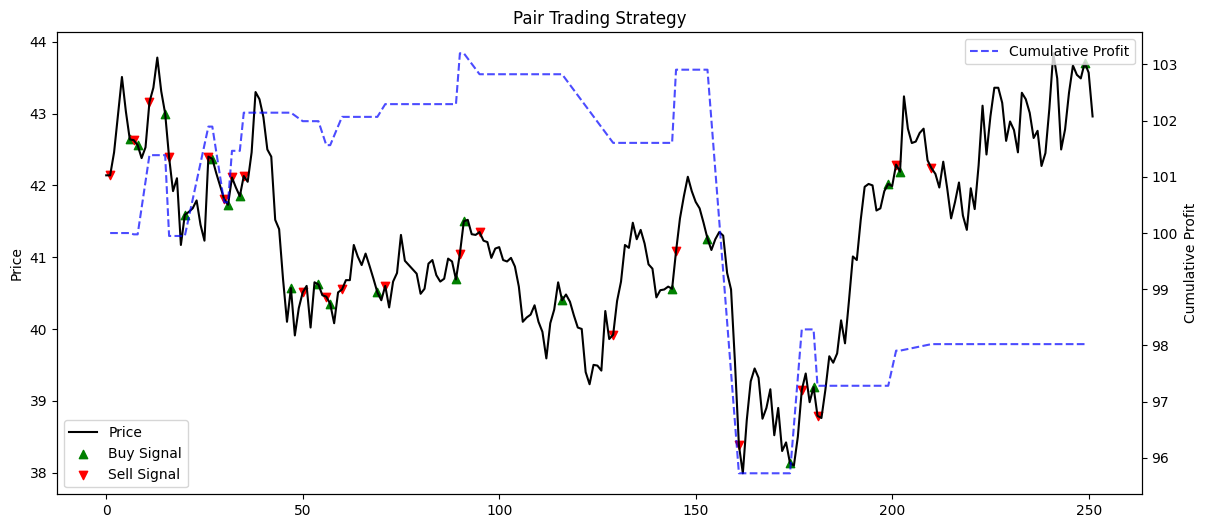

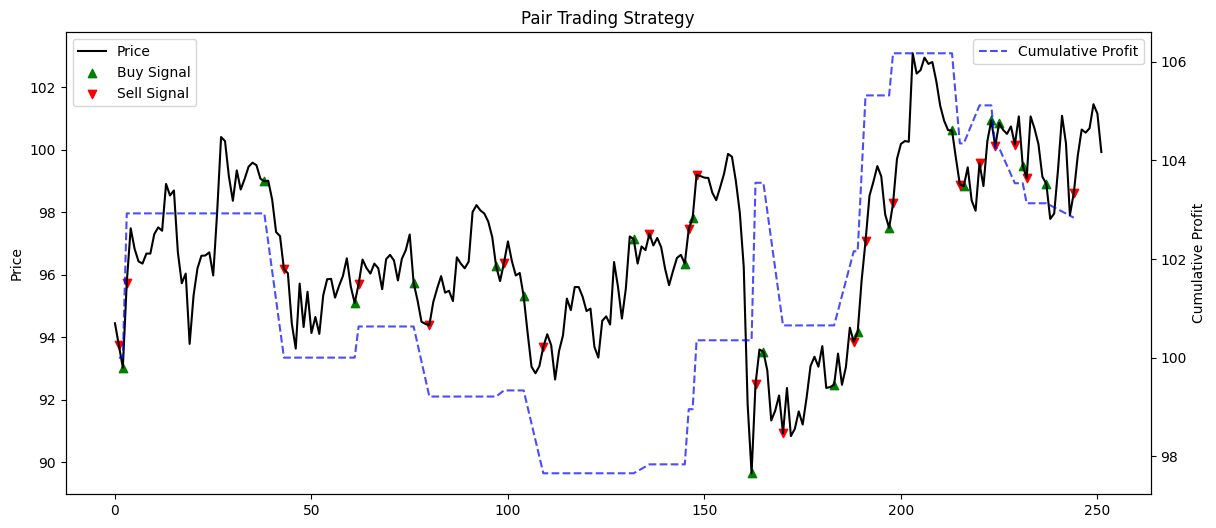

In [58]:
signals_df1 = signals_zscore_evolution(df['KO'], df['PEP'])
profit_df1 = calculate_profit(signals_df1, df['KO'])
ax1, _ = plot_strategy(df['KO'], signals_df1, profit_df1)

signals_df2 = signals_zscore_evolution(df['KO'], df['PEP'], first_ticker=False)
profit_df2 = calculate_profit(signals_df2, df['PEP'])
ax2, _ = plot_strategy(df['PEP'], signals_df2, profit_df2)

plt.show()


In [59]:
# Print the final profits
print(f"Final Profit for KO: ${profit_df1['Profit'].iloc[-1]:,.2f}")
print(f"Final Profit for PEP: ${profit_df2['Profit'].iloc[-1]:,.2f}")

Final Profit for KO: $98.02
Final Profit for PEP: $102.84
